# Customer Churn Prediction: From Data to Model Evaluation

**Experiment 2 – Classification with Logistic Regression**

Predicting whether a telecom customer will leave (churn), using their contract, services and charges.

**To run on Kaggle:** click **Add Input**, add the *Telco Customer Churn* dataset (by blastchar), then **Run All**.

In [1]:
# 1. Import the libraries
# We need pandas for tables, numpy for maths, matplotlib for charts and scikit-learn for the
# models and metrics.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             RocCurveDisplay, PrecisionRecallDisplay)

In [2]:
# 2. Load the churn CSV
# pd.read_csv loads the file into a DataFrame called data, and the print confirms it loaded
# (7,043 rows, 21 columns).

data_path = "/kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"
data = pd.read_csv(data_path)

print("Loaded:", data_path)
print("Rows:", len(data), "| Columns:", len(data.columns))

Loaded: /kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv
Rows: 7043 | Columns: 21


In [3]:
# 3. Explore The Dataset
# 3.1 First five customers
# head() shows the first 5 customers, so we can check the columns. Churn is what we want to
# predict.

data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# 3.2 Last five customers
# tail() shows the last 5 customers, to make sure the whole file loaded properly.

data.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
# 3.3 Rows and columns
# shape gives (rows, columns): 7,043 customers and 2 classes, so it meets the brief.

data.shape

(7043, 21)

In [6]:
# 3.4 Column types and missing counts
# info() shows most columns are text, and TotalCharges is text even though it should be a number.

data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [7]:
# 3.5 Duplicates and missing values
# There are no duplicate rows and no normal missing values.

print("Duplicate rows:", data.duplicated().sum())
print("Missing values:", data.isnull().sum().sum())

Duplicate rows: 0
Missing values: 0


In [8]:
# 3.6 Find the problem in TotalCharges
# We look for blank TotalCharges values and find 11. All of them have tenure 0, so they are
# brand-new customers.

blank_rows = data["TotalCharges"].str.strip() == ""
print("Blank TotalCharges values:", blank_rows.sum())
display(data.loc[blank_rows, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

Blank TotalCharges values: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [ ]:
# What I noticed:
# - All 11 blank TotalCharges belong to customers with tenure 0.
# - They are new customers, so their total is really 0.

In [9]:
# 3.7 Fix TotalCharges
# New customers haven't been charged yet, so we set the blanks to 0 and convert the column to
# numbers.

data["TotalCharges"] = pd.to_numeric(data["TotalCharges"].str.strip().replace("", "0"))
print("TotalCharges type is now:", data["TotalCharges"].dtype)

TotalCharges type is now: float64


Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


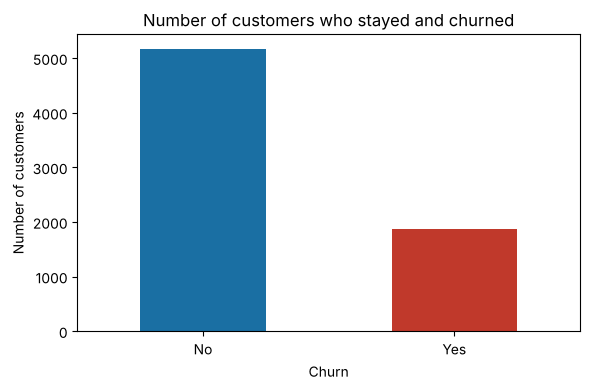

In [10]:
# 3.8 How many customers churned?
# Only 26.5% of customers churned, so the classes are imbalanced.

print(data["Churn"].value_counts())
print(data["Churn"].value_counts(normalize=True).round(3))

data["Churn"].value_counts().plot(kind="bar", color=["#1A6FA3", "#C0392B"], figsize=(6, 4))
plt.title("Number of customers who stayed and churned")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# What I noticed:
# - Only 26.5% of customers churned, so churners are the rare class.
# - This means accuracy alone can be misleading.

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64


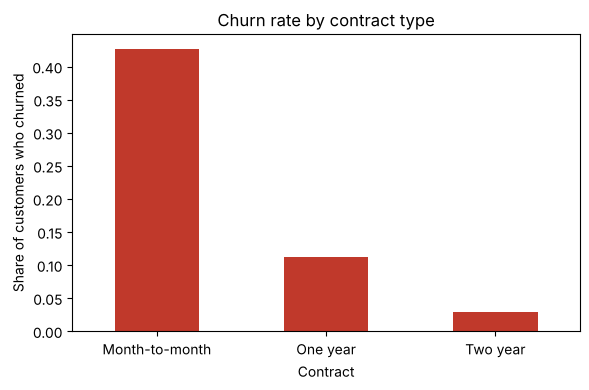

In [11]:
# 3.9 Churn rate by contract
# The churn rate shows month-to-month customers churn the most (42.7%). Two-year contracts churn
# the least (2.8%).

churn_by_contract = data.groupby("Contract")["Churn"].apply(lambda answers: (answers == "Yes").mean())
print(churn_by_contract.round(3))

churn_by_contract.plot(kind="bar", color="#C0392B", figsize=(6, 4))
plt.title("Churn rate by contract type")
plt.ylabel("Share of customers who churned")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

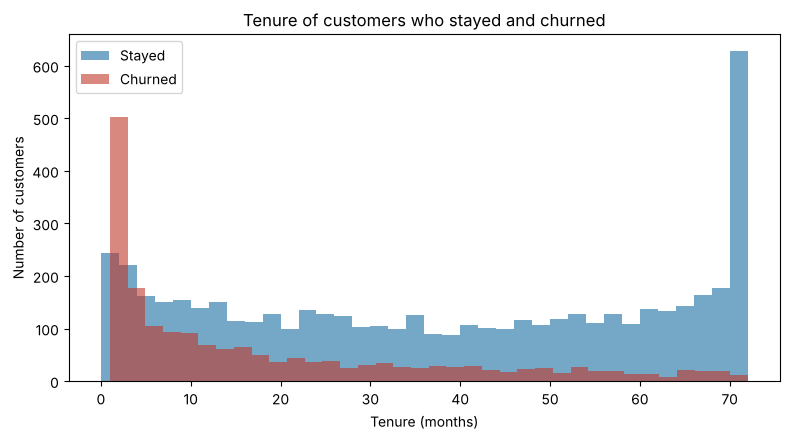

In [12]:
# 3.10 Tenure for stayed vs churned
# Each bar is a group of customers. So churners are mostly new customers with low tenure, and
# long-term customers rarely leave.

plt.figure(figsize=(8, 4.5))
plt.hist(data.loc[data["Churn"] == "No", "tenure"], bins=36, alpha=0.6, label="Stayed", color="#1A6FA3")
plt.hist(data.loc[data["Churn"] == "Yes", "tenure"], bins=36, alpha=0.6, label="Churned", color="#C0392B")
plt.xlabel("Tenure (months)")
plt.ylabel("Number of customers")
plt.title("Tenure of customers who stayed and churned")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# What I noticed:
# - Month-to-month customers churn far more than those on 1- or 2-year contracts.
# - Most churners leave in their first months.

In [13]:
# 4. Opting for Input and Targets
# 4.1 Create the input table X
# X holds the inputs. We drop customerID (just a label) and Churn (the answer).

X = data.drop(columns=["customerID", "Churn"])

In [14]:
# 4.2 Check X
# A quick check that X has the right columns.

X.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


In [15]:
# 4.3 Create the target y
# y holds the target: 1 if the customer churned, 0 if they stayed.

y = (data["Churn"] == "Yes").astype(int)

In [16]:
# 4.4 Check y
# A quick check that y has the values we expect.

y.head()

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

In [17]:
# 5. Data Preparation for Splitting
# 5.1 Encode the text columns
# The model only understands numbers, so get_dummies turns each text column into 0/1 columns.

X = pd.get_dummies(X, drop_first=True, dtype=int)
print("Columns after encoding:", X.shape[1])
X.head()

Columns after encoding: 30


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0


In [18]:
# 5.2 Split into training and test sets
# 80% trains the model and 20% tests it. stratify=y keeps the same churn rate (26.5%) in both
# sets.

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [19]:
# 5.3 Confirm the split
# Checks the sizes and confirms both sets have the same churn rate.

print("Training customers:", len(X_train), "| churn rate:", round(y_train.mean(), 3))
print("Test customers:", len(X_test), "| churn rate:", round(y_test.mean(), 3))

Training customers: 5634 | churn rate: 0.265
Test customers: 1409 | churn rate: 0.265


In [20]:
# 5.4 Scale the features
# StandardScaler puts all columns on the same scale. It learns from the training data only, so no
# test information leaks in.

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [21]:
# ============================================================
# 6. BUILD AND TRAIN THE MODEL
# ============================================================
# 6.1 Create the model
# Creates the Logistic Regression model, which predicts the probability that a customer churns.

model = LogisticRegression(max_iter=1000)

In [22]:
# 6.2 Train the model
# fit() learns the weights from the training customers only.

model.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [23]:
# ============================================================
# 7. PREDICT CHURN FOR THE TEST CUSTOMERS
# ============================================================
# 7.1 Make predictions
# predict() gives 0 or 1 for each test customer, and predict_proba() gives the probability of
# churning.

churn_prediction = model.predict(X_test_scaled)
churn_probability = model.predict_proba(X_test_scaled)[:, 1]

In [24]:
# 7.2 First ten predictions
# The first 10 predictions (1 = churn, 0 = stay).

churn_prediction[:10]

array([0, 1, 0, 0, 0, 1, 0, 0, 0, 0])

In [25]:
# 7.3 Actual vs predicted table
# Puts real and predicted answers side by side, with the probability and whether each prediction
# was correct.

comparison = pd.DataFrame({
    "Original row": y_test.index,
    "Actual churn": y_test.to_numpy(),
    "Predicted churn": churn_prediction,
    "Churn probability": churn_probability
})
comparison["Correct"] = comparison["Actual churn"] == comparison["Predicted churn"]
display(comparison.head(10).round(3))

,Original row,Actual churn,Predicted churn,Churn probability,Correct
0,437,0,0,0.045,True
1,2280,0,1,0.683,False
2,2235,0,0,0.057,True
3,4460,0,0,0.408,True
4,3761,0,0,0.022,True
5,5748,0,1,0.604,False
6,3568,0,0,0.452,True
7,2976,0,0,0.131,True
8,5928,0,0,0.003,True
9,1639,1,0,0.394,False


In [26]:
# ============================================================
# 8. EVALUATE THE MODEL
# ============================================================
# 8.1 Accuracy
# Accuracy is the share of all customers predicted correctly: 80.7%.

accuracy = accuracy_score(y_test, churn_prediction)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.8070


In [27]:
# 8.2 Precision
# Precision: when the model says 'churn', how often it is right (65.8%).

precision = precision_score(y_test, churn_prediction)
print(f"Precision: {precision:.4f}")

Precision: 0.6584


In [28]:
# 8.3 Recall
# Recall: of the customers who really churned, how many we caught (56.7%).

recall = recall_score(y_test, churn_prediction)
print(f"Recall: {recall:.4f}")

Recall: 0.5668


In [29]:
# 8.4 F1 score
# F1 combines precision and recall into one score (0.609).

f1 = f1_score(y_test, churn_prediction)
print(f"F1 score: {f1:.4f}")

F1 score: 0.6092


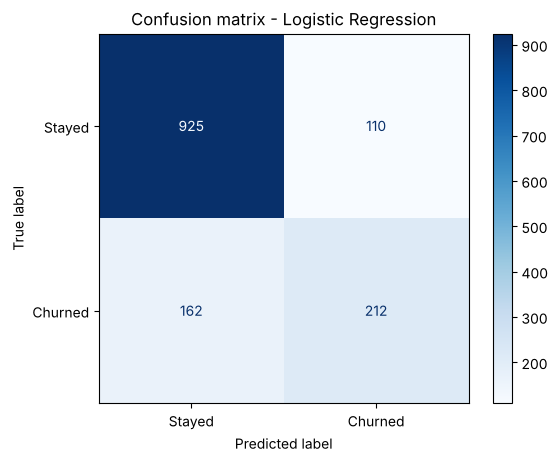

In [30]:
# 8.5 Confusion matrix
# The confusion matrix shows correct answers, false alarms and missed churners. 162 churners were
# missed.

ConfusionMatrixDisplay.from_predictions(y_test, churn_prediction, display_labels=["Stayed", "Churned"], cmap="Blues")
plt.title("Confusion matrix - Logistic Regression")
plt.show()

In [31]:
# 8.6 Classification report
# Shows precision, recall and F1 for both classes in one table.

print(classification_report(y_test, churn_prediction, target_names=["Stayed", "Churned"]))

              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
     Churned       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [32]:
# 8.7 Baseline
# The baseline always says 'No churn'. It gets 73.5% accuracy but catches 0 churners, so accuracy
# alone is misleading.

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_scaled, y_train)
baseline_prediction = baseline.predict(X_test_scaled)

baseline_accuracy = accuracy_score(y_test, baseline_prediction)
baseline_recall = recall_score(y_test, baseline_prediction)
print(f"Baseline accuracy: {baseline_accuracy:.4f}")
print(f"Baseline recall: {baseline_recall:.4f}")

Baseline accuracy: 0.7346
Baseline recall: 0.0000


In [33]:
# 8.8 Training vs test
# Training and test scores are almost the same, so the model is not overfitting.

train_prediction = model.predict(X_train_scaled)
print(f"Training accuracy: {accuracy_score(y_train, train_prediction):.4f} | F1: {f1_score(y_train, train_prediction):.4f}")
print(f"Test accuracy:     {accuracy:.4f} | F1: {f1:.4f}")

Training accuracy: 0.8065 | F1: 0.6022
Test accuracy:     0.8070 | F1: 0.6092


In [34]:
# 8.9 Results in plain words
# Prints the main results in plain sentences, so they are easy to read.

caught = ((churn_prediction == 1) & (y_test == 1)).sum()
print(f"We evaluated {len(y_test)} customers who were held back from training.")
print(f"The model was correct for {accuracy:.1%} of them.")
print(f"It caught {caught} of the {y_test.sum()} customers who really churned (recall {recall:.1%}).")
print(f"When it predicted churn, it was right {precision:.1%} of the time (precision).")

if accuracy > baseline_accuracy:
    print(f"It beats the baseline accuracy of {baseline_accuracy:.1%}, which caught no churners at all.")
else:
    print("It does not beat the baseline accuracy.")

We evaluated 1409 customers who were held back from training.
The model was correct for 80.7% of them.
It caught 212 of the 374 customers who really churned (recall 56.7%).
When it predicted churn, it was right 65.8% of the time (precision).
It beats the baseline accuracy of 73.5%, which caught no churners at all.


In [ ]:
# What I noticed:
# - 80.7% accuracy is only a bit better than the baseline's 73.5%.
# - The model missed 162 of 374 churners (recall 56.7%), because it leans towards 'No churn'.

In [35]:
# 9. Handling Class Imbalance
# 9.1 Class weights
# class_weight='balanced' makes mistakes on churners count more, because they are the rare class.

weighted_model = LogisticRegression(max_iter=1000, class_weight="balanced")
weighted_model.fit(X_train_scaled, y_train)
weighted_prediction = weighted_model.predict(X_test_scaled)

print(f"Accuracy: {accuracy_score(y_test, weighted_prediction):.4f}")
print(f"Precision: {precision_score(y_test, weighted_prediction):.4f}")
print(f"Recall: {recall_score(y_test, weighted_prediction):.4f}")
print(f"F1 score: {f1_score(y_test, weighted_prediction):.4f}")

Accuracy: 0.7402
Precision: 0.5069
Recall: 0.7861
F1 score: 0.6164


,Accuracy,Precision,Recall,F1
No adjustment,0.8070,0.6584,0.5668,0.6092
Class weights,0.7402,0.5069,0.7861,0.6164


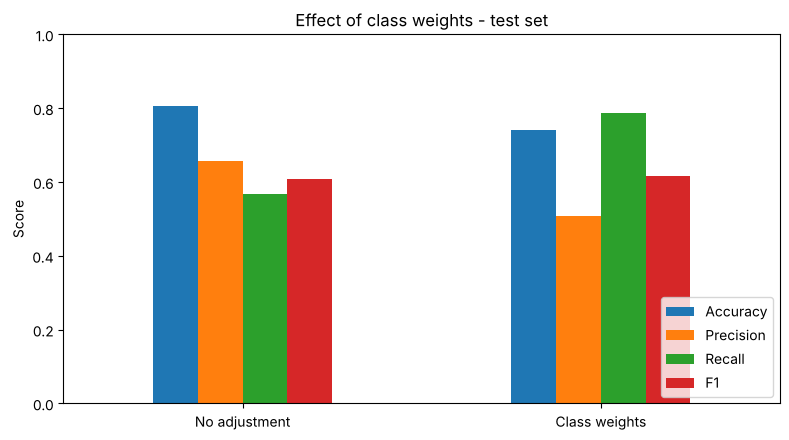

In [36]:
# 9.2 Compare with the original model
# Compares the original and class-weighted models side by side in a table and a chart.

imbalance_predictions = {
    "No adjustment": churn_prediction,
    "Class weights": weighted_prediction,
}
imbalance_results = pd.DataFrame({
    "Accuracy": [accuracy_score(y_test, p) for p in imbalance_predictions.values()],
    "Precision": [precision_score(y_test, p) for p in imbalance_predictions.values()],
    "Recall": [recall_score(y_test, p) for p in imbalance_predictions.values()],
    "F1": [f1_score(y_test, p) for p in imbalance_predictions.values()],
}, index=imbalance_predictions.keys())
display(imbalance_results.round(4))

imbalance_results.plot(kind="bar", figsize=(8, 4.5), rot=0)
plt.title("Effect of class weights - test set")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
# What I noticed:
# - Class weights raised recall from 56.7% to 78.6%, so the model catches 294 churners instead of 212.
# - Precision dropped to about 51% (more false alarms), but F1 improved slightly.

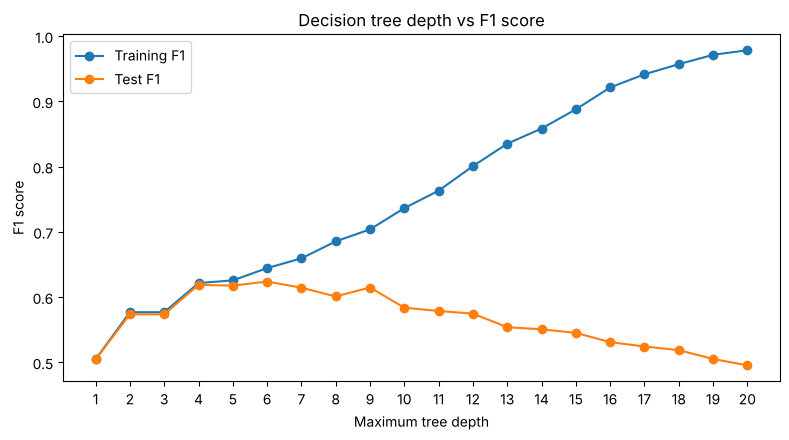

Depth with the best test F1: 6


In [37]:
# 10. Decision Tree Overfitting (Extension)
# 10.1 Decision tree depth
# Trains trees of depth 1 to 20. The training score keeps rising but the test score drops after
# about depth 6, which shows overfitting.

depths = range(1, 21)
train_f1_scores = []
test_f1_scores = []

for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, class_weight="balanced", random_state=42)
    tree.fit(X_train_scaled, y_train)
    train_f1_scores.append(f1_score(y_train, tree.predict(X_train_scaled)))
    test_f1_scores.append(f1_score(y_test, tree.predict(X_test_scaled)))

plt.figure(figsize=(8, 4.5))
plt.plot(depths, train_f1_scores, marker="o", label="Training F1")
plt.plot(depths, test_f1_scores, marker="o", label="Test F1")
plt.xlabel("Maximum tree depth")
plt.ylabel("F1 score")
plt.title("Decision tree depth vs F1 score")
plt.xticks(depths)
plt.legend()
plt.tight_layout()
plt.show()

best_depth = depths[int(np.argmax(test_f1_scores))]
print("Depth with the best test F1:", best_depth)

In [ ]:
# What I noticed:
# - The test F1 is best around depth 4-6.
# - Deeper trees score almost 100% on training data but worse on test data, which is overfitting.

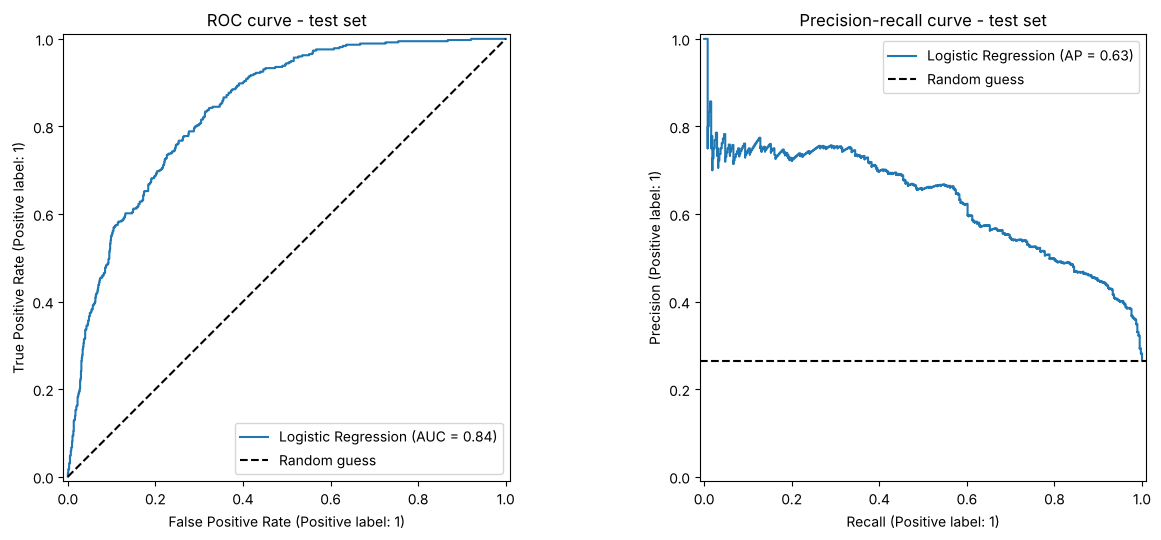

ROC-AUC: 0.8414


In [38]:
# 11. ROC and Precision-Recall Curves
# 11.1 ROC and precision-recall curves
# The ROC curve shows how well the model ranks churners. The PR curve shows the trade-off between
# precision and recall.

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

RocCurveDisplay.from_estimator(weighted_model, X_test_scaled, y_test, name="Logistic Regression", ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[0].set_title("ROC curve - test set")
axes[0].legend()

PrecisionRecallDisplay.from_estimator(weighted_model, X_test_scaled, y_test, name="Logistic Regression", ax=axes[1])
axes[1].axhline(y_test.mean(), color="k", linestyle="--", label="Random guess")
axes[1].set_title("Precision-recall curve - test set")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"ROC-AUC: {roc_auc_score(y_test, weighted_model.predict_proba(X_test_scaled)[:, 1]):.4f}")

In [ ]:
# What I noticed:
# - ROC-AUC is 0.841, well above random guessing (0.5).
# - The PR curve shows that catching more churners means more false alarms.

Summary

In this experiment, I wanted to predict whether a telecom customer would churn (leave the company). I used the Telco Customer Churn dataset, which consists of 7,043 customers and 19 features. Namely, contract type, monthly charges, the services they use, and how long they've been a customer (tenure). Before any training, I sifted through the data and noticed that only 26.5% of customers churned, so the two classes are imbalanced. I also found 11 blank values in TotalCharges, but they all belonged to brand-new customers with a tenure of 0, so I set them to 0.

For data preparation, I turned all the text columns into 0/1 columns with get_dummies, which gave 30 columns. I then split the data into 80% training and 20% testing, using stratify so both sets kept the same churn rate. Lastly, I scaled the features with StandardScaler, and made sure the scaling was only learned from the training data, so the test data stayed completely unseen.

Logistic Regression got an accuracy of 80.7%, a precision of 65.8%, a recall of 56.7%, and an F1 score of 0.609. At first the accuracy looks pretty good, but a simple baseline that always says "No churn" already gets 73.5% accuracy without catching a single churner. That showed me that accuracy can be very misleading when the classes are imbalanced. The confusion matrix made the problem clear, since the model missed 162 of the 374 customers who actually churned, because it leans towards predicting "No churn". The training and test scores were very similar, so the model didn't overfit.

To deal with the imbalance, I retrained the model with class weights, which makes mistakes on churners count more. This raised recall to 78.6%, so the model caught 294 churners instead of 212. The trade-off was more false alarms, with precision dropping to about 51%, but the F1 score still went up slightly to 0.616. The ROC curve gave an AUC of 0.841, which means the model is pretty good at ranking risky customers above safe ones.

As an extension, I trained decision trees of different depths to see overfitting in action. The test score was best at around depth 4 to 6. And much to my surprise, as the trees got deeper, the training F1 went up to 0.978 while the test F1 dropped to 0.495, so the tree was memorising the training customers.

Overall, I found Logistic Regression to be fast, simple, and very easy to explain, and it gave consistent results on both training and test data. Its main weakness is that the default 0.5 cut-off doesn't suit imbalanced data, which is why it missed so many churners at first. The dataset is also a single snapshot of a fictional company, so it can't tell us when a customer will leave. Next time, I would try other models such as Random Forest, and choose the decision threshold based on what a missed churner actually costs the business.

### References
- BlastChar (n.d.) *Telco Customer Churn* [dataset]. Kaggle. Available at: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
- IBM (2019) *Telco customer churn (sample dataset)*. Available at: https://github.com/IBM/telco-customer-churn-on-icp4d
- Pedregosa, F. *et al.* (2011) 'Scikit-learn: Machine learning in Python', *Journal of Machine Learning Research*, 12, pp. 2825–2830.